## 1. Hugging Face Login

#### This imports the token from Kaggle Secrets, so make sure the secret is set correctly before running the code.

In [1]:
from collections import Counter
from tqdm.auto import tqdm
import pickle
import re
from collections import Counter, defaultdict

In [2]:
import os
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

print("Hugging Face login successful.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


## 2. Check GPU

In [3]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


## 3. Configuration

#### this is sample configuration, you are free to modify any parameter to train the best performing model

In [4]:
import os
import random
import json
import time
import math
import zipfile
import shutil

# Hugging Face dataset
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"

# You can use any of the 4 train files or all the files for pre-training the legal model
TRAIN_FILE = "Phase_1_Pretraining/Train/train_supreme_court.json"
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

SMOKE = False

# Training configuration
TRAIN_TOKENS = 300_000 if SMOKE else 200_000_000
VAL_TOKENS = 20_000 if SMOKE else 5_000_000
TRAIN_BLOCK_SIZE = 256 if SMOKE else 2048
EPOCHS = 1
SEED = 42
random.seed(SEED)
MODEL_CONTEXT_LENGTH = 256 if SMOKE else 2048
N_EMBD = 64 if SMOKE else 1024
N_LAYER = 2 if SMOKE else 8
N_HEAD = 2 if SMOKE else 8

VOCAB_SIZE = 512 if SMOKE else 10000
TOKENIZER_TRAIN_CHARS = 200_000 if SMOKE else 500_000   # characters of text the BPE trains on
MAX_DOC_CHARS = 20_000 if SMOKE else None 


TOKENIZE_TIME_BUDGET_SEC = 16 * 60 # tokenization time cap


# Generation
NUM_TEST_PROMPTS = 8 if SMOKE else None
TARGET_GENERATION_WORDS = 128
MAX_GENERATION_TOKENS = 64 if SMOKE else 384
TEMPERATURE = 0.1
TOP_P = 0.95

# Kaggle output
OUTPUT_TAG = "smoke" if SMOKE else "full"
OUTPUT_DIR = f"/kaggle/working/cs781_phase1_{OUTPUT_TAG}"
MODEL_OUTPUT_DIR = os.path.join(
    OUTPUT_DIR,
    "legal-gpt2-final"
)
PREDICTION_PATH = os.path.join(
    OUTPUT_DIR,
    "prediction.json"
)
SUBMISSION_ZIP = os.path.join(
    OUTPUT_DIR,
    "submission.zip"
)
LOSS_PLOT_PATH = os.path.join(
    OUTPUT_DIR,
    "training_validation_loss.png"
)
os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)
print("Configuration loaded.")

Configuration loaded.


## 4. Load Tokenizer

In [5]:


SPECIAL_TOKENS = ["<pad>", "<unk>", "<s>", "</s>"]  # fixed ids 0-3, never merged

class BPETokenizer:
    def __init__(self):
        self.id_to_bytes = {}
        self.bytes_to_id = {}
        self.merges = {}
        self.merge_order = []
        self.merge_ranks = {}  # Precomputed pair -> rank for fast encoding
        self.cache = {}        # Chunk lookup cache
        self._vocab_size = 0
        
        # Splits on whitespace+word or just whitespace. 
        # Guarantees round-trip: "".join(chunks) == text
        self.split_pattern = re.compile(r'\s*\S+|\s+')

    def train(self, text: str, vocab_size: int):
        # 1. Setup base vocabulary
        for i, tok in enumerate(SPECIAL_TOKENS):
            b = tok.encode("utf-8")
            self.id_to_bytes[i] = b
            self.bytes_to_id[b] = i

        next_id = len(SPECIAL_TOKENS)
        byte_to_base_id = {}
        for value in range(256):
            b = bytes([value])
            self.id_to_bytes[next_id] = b
            self.bytes_to_id[b] = next_id
            byte_to_base_id[value] = next_id
            next_id += 1

        # 2. Split text into chunks and get frequencies
        chunks = self.split_pattern.findall(text)
        chunk_counts = Counter(chunks)
        
        # 3. Store each distinct chunk as a tuple of base byte ids
        chunk_to_ids = {
            chunk: tuple(byte_to_base_id[b] for b in chunk.encode("utf-8"))
            for chunk in chunk_counts
        }

        # 4. Initialize weighted pair counts and the pair-to-chunk index
        pair_counts = Counter()
        pair_to_chunks = defaultdict(set)
        
        def get_pairs(ids):
            return [(ids[i], ids[i+1]) for i in range(len(ids) - 1)]

        for chunk, ids in chunk_to_ids.items():
            count = chunk_counts[chunk]
            for pair in get_pairs(ids):
                pair_counts[pair] += count
                pair_to_chunks[pair].add(chunk)

        target = vocab_size
        num_merges = target - next_id
        pbar = tqdm(total=num_merges, desc="Training BPE")

        # 5. Iteratively merge the best pair
        while next_id < target:
            if not pair_counts:
                break

            max_freq = max(pair_counts.values())
            if max_freq <= 1:
                break

            # Min tuple tie-breaker matching your original behavior
            best_pair = min(p for p, c in pair_counts.items() if c == max_freq)

            new_id = next_id
            self.merges[best_pair] = new_id
            self.merge_order.append(best_pair)
            self.merge_ranks[best_pair] = len(self.merge_order) - 1
            
            self.id_to_bytes[new_id] = self.id_to_bytes[best_pair[0]] + self.id_to_bytes[best_pair[1]]
            self.bytes_to_id[self.id_to_bytes[new_id]] = new_id

            # 6. Update only the chunks containing the merged pair
            chunks_to_update = list(pair_to_chunks[best_pair])
            for chunk in chunks_to_update:
                old_ids = chunk_to_ids[chunk]
                count = chunk_counts[chunk]
                
                # Subtract old pair combinations
                for pair in get_pairs(old_ids):
                    pair_counts[pair] -= count
                    if pair_counts[pair] <= 0:
                        del pair_counts[pair]
                    if chunk in pair_to_chunks[pair]:
                        pair_to_chunks[pair].remove(chunk)
                
                # Apply the merge inside this chunk
                new_ids = []
                i = 0
                while i < len(old_ids):
                    if i < len(old_ids) - 1 and (old_ids[i], old_ids[i+1]) == best_pair:
                        new_ids.append(new_id)
                        i += 2
                    else:
                        new_ids.append(old_ids[i])
                        i += 1
                new_ids = tuple(new_ids)
                chunk_to_ids[chunk] = new_ids
                
                # Add new pair combinations created by the merge
                for pair in get_pairs(new_ids):
                    pair_counts[pair] += count
                    pair_to_chunks[pair].add(chunk)

            next_id += 1
            pbar.update(1)

        pbar.close()
        self._vocab_size = next_id

    def encode(self, text: str):
        chunks = self.split_pattern.findall(text)
        out_ids = []
        
        for chunk in chunks:
            # Check the dictionary cache first
            if chunk in self.cache:
                out_ids.extend(self.cache[chunk])
                continue
            
            # Cache miss: break into bytes and process
            chunk_bytes = chunk.encode("utf-8")
            ids = [self.bytes_to_id[bytes([b])] for b in chunk_bytes]
            
            # Merge until no adjacent pair has a valid merge rank
            while len(ids) > 1:
                pairs = [(ids[i], ids[i+1]) for i in range(len(ids) - 1)]
                best_pair = None
                best_rank = float('inf')
                
                # Find the pair with the lowest rank
                for p in pairs:
                    rank = self.merge_ranks.get(p, float('inf'))
                    if rank < best_rank:
                        best_rank = rank
                        best_pair = p
                
                if best_pair is None:
                    break  # No more valid merges for this chunk
                    
                # Apply the best merge to all occurrences in the chunk
                new_id = self.merges[best_pair]
                new_ids = []
                i = 0
                while i < len(ids):
                    if i < len(ids) - 1 and (ids[i], ids[i+1]) == best_pair:
                        new_ids.append(new_id)
                        i += 2
                    else:
                        new_ids.append(ids[i])
                        i += 1
                ids = new_ids
            
            # Store result in cache and append
            self.cache[chunk] = ids
            out_ids.extend(ids)
            
        return out_ids

    def decode(self, ids):
        out = b"".join(self.id_to_bytes[i] for i in ids)
        return out.decode("utf-8", errors="replace")

    def get_vocab_size(self):
        return self._vocab_size

    @property
    def vocab_size(self):
        return self._vocab_size


def train_tokenizer(train_text: str, vocab_size: int):
    """Train the A1 BPE tokenizer on `train_text` and return it, ready for A3."""
    tok = BPETokenizer()
    tok.train(train_text, vocab_size)
    return tok

In [6]:
# from transformers import AutoTokenizer

# tokenizer = AutoTokenizer.from_pretrained("openai-community/gpt2")
# tokenizer.pad_token = tokenizer.eos_token
# print("Vocabulary size:", len(tokenizer))

## 5. Download Training Data From Hugging Face

In [7]:
from huggingface_hub import hf_hub_download

train_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TRAIN_FILE,
    repo_type="dataset",
    token=HF_TOKEN
)

print("Training file:")
print(train_file_path)

Phase_1_Pretraining/Train/train_supreme_(…): reconstructing file:   0%|          |  0.00B / 1.32GB            

Phase_1_Pretraining/Train/train_supreme_(…): downloading bytes:           |  0.00B            

Training file:
/root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_supreme_court.json


In [8]:
with open(train_file_path, "r", encoding="utf-8") as f:
    records = json.load(f)

TOKENIZER_PATH = os.path.join(OUTPUT_DIR, "bpe_tokenizer.pkl")
if os.path.exists(TOKENIZER_PATH):
    with open(TOKENIZER_PATH, "rb") as f:
        tokenizer = pickle.load(f)
else:
    idx = list(range(len(records)))
    random.Random(SEED).shuffle(idx)          # random sample of documents
    parts, n = [], 0
    for i in idx:
        parts.append(records[i]["text"]); n += len(parts[-1])
        if n >= TOKENIZER_TRAIN_CHARS:
            break
    tokenizer = train_tokenizer("\n".join(parts)[:TOKENIZER_TRAIN_CHARS], VOCAB_SIZE)
    with open(TOKENIZER_PATH, "wb") as f:
        pickle.dump(tokenizer, f)

NUM_SPECIAL = len(SPECIAL_TOKENS)               # 4
PAD_ID = tokenizer.bytes_to_id[b"<pad>"]        # 0
BOS_ID = tokenizer.bytes_to_id[b"<s>"]          # 2
EOS_ID = tokenizer.bytes_to_id[b"</s>"]         # 3
print("Vocabulary size:", tokenizer.vocab_size)

Training BPE:   0%|          | 0/9740 [00:00<?, ?it/s]

Vocabulary size: 10000


In [9]:
import numpy as np
from tqdm import tqdm

assert tokenizer.vocab_size < 65536

train_parts, val_parts = [], []
n_train = n_val = 0
rng = random.Random(SEED)
t0 = time.time()
stopped_by_time = False

for rec in tqdm(records, desc="Tokenizing records"):
    if time.time() - t0 > TOKENIZE_TIME_BUDGET_SEC:
        stopped_by_time = True
        break
    is_val = rng.random() < 0.05
    if (is_val and n_val >= VAL_TOKENS) or (not is_val and n_train >= TRAIN_TOKENS):
        continue
    text = rec["text"][:MAX_DOC_CHARS] if MAX_DOC_CHARS else rec["text"]
    ids = tokenizer.encode(text) + [EOS_ID]
    if is_val:
        ids = ids[:VAL_TOKENS - n_val]
        val_parts.append(np.array(ids, dtype=np.uint16)); n_val += len(ids)
    else:
        ids = ids[:TRAIN_TOKENS - n_train]
        train_parts.append(np.array(ids, dtype=np.uint16)); n_train += len(ids)
    if n_train >= TRAIN_TOKENS and n_val >= VAL_TOKENS:
        break

train_arr, val_arr = np.concatenate(train_parts), np.concatenate(val_parts)
np.save(os.path.join(OUTPUT_DIR, "train_ids.npy"), train_arr)
np.save(os.path.join(OUTPUT_DIR, "val_ids.npy"), val_arr)
print(f"Train tokens: {len(train_arr):,}  Validation tokens: {len(val_arr):,}")
print(f"Elapsed: {(time.time() - t0) / 60:.1f} min" + ("  (STOPPED BY TIME CAP)" if stopped_by_time else ""))

Tokenizing records:  75%|███████▍  | 41552/55549 [02:15<00:45, 306.87it/s]


Train tokens: 200,000,000  Validation tokens: 5,000,000
Elapsed: 2.3 min


## 6. Create Train and Validation Tokens Set

## 7. Create Token Blocks

In [10]:
class BlockDataset(torch.utils.data.Dataset):
    def __init__(self, arr, block):
        n = (len(arr) // block) * block
        self.blocks = arr[:n].reshape(-1, block)
    def __len__(self):
        return len(self.blocks)
    def __getitem__(self, i):
        return {"input_ids": torch.from_numpy(self.blocks[i].astype(np.int64))}

train_dataset = BlockDataset(train_arr, TRAIN_BLOCK_SIZE)
val_dataset = BlockDataset(val_arr, TRAIN_BLOCK_SIZE)

print("Training sequences:", len(train_dataset))
print("Validation sequences:", len(val_dataset))

Training sequences: 97656
Validation sequences: 2441


## 8. Create Datasets

In [11]:
# from datasets import Dataset

# train_dataset = Dataset.from_dict({"input_ids": train_blocks})
# val_dataset = Dataset.from_dict({"input_ids": val_blocks})

# print(train_dataset)
# print(val_dataset)

## 9. Define The Model

In [12]:
# ============================================================
# CELL 1 — Decoder-only Transformer (your A3 Q1 code, unchanged except the 2 marked LayerNorm lines)
# Replaces: §9 "Define The Model" (GPT2Config / GPT2LMHeadModel) and the DataCollator cell.
# ============================================================
import math
from dataclasses import dataclass, asdict
import torch
import torch.nn as nn
import torch.nn.functional as F


# ---------- A3 Q1.1: manual causal multi-head self-attention ----------
class CausalSelfAttention(nn.Module):
    def __init__(self, d_model: int, n_heads: int, n_kv_heads: int, max_seq_len: int, dropout: float = 0.0, attention_scale=None):
        super().__init__()
        assert d_model % n_heads == 0
        assert n_heads % n_kv_heads == 0, "n_heads must be divisible by n_kv_heads"
        self.n_heads = n_heads
        self.n_kv_heads = n_kv_heads
        self.n_rep = n_heads // n_kv_heads   # how many query heads share each kv head
        self.d_head = d_model // n_heads
        # Preserve the Q1.4 hook in later questions. None -> standard 1/sqrt(d_head).
        self.attention_scale = (1.0 / math.sqrt(self.d_head)) if attention_scale is None else float(attention_scale)

        # TODO: q_proj maps d_model -> n_heads * d_head (as before).
        # TODO: k_proj, v_proj map d_model -> n_kv_heads * d_head (SMALLER than before
        #       whenever n_kv_heads < n_heads -- this is where the parameter savings
        #       and (in a real serving system) the KV-cache savings come from).
        self.q_proj = nn.Linear(d_model,n_heads * self.d_head)
        self.k_proj = nn.Linear(d_model,n_kv_heads * self.d_head)
        self.v_proj = nn.Linear(d_model,n_kv_heads * self.d_head)
        self.out_proj = nn.Linear(n_heads * self.d_head, d_model, bias=False)

        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)
        mask = torch.tril(torch.ones(max_seq_len, max_seq_len, dtype=torch.bool))
        self.register_buffer("causal_mask", mask, persistent=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, T, C = x.shape
        # TODO 1: project q -> (B, n_heads, T, d_head); k, v -> (B, n_kv_heads, T, d_head)
        q = self.q_proj(x).view(B, T, self.n_heads, self.d_head).transpose(1,2)
        k = self.k_proj(x).view(B, T, self.n_kv_heads, self.d_head).transpose(1,2)
        v = self.v_proj(x).view(B, T, self.n_kv_heads, self.d_head).transpose(1,2)
        # TODO 2: expand k and v from n_kv_heads to n_heads by repeating each kv head
        #         `self.n_rep` times (torch.repeat_interleave along the head dim is the
        #         natural tool here) so shapes line up for a standard batched matmul.
        if self.n_rep > 1:
            k = k.repeat_interleave(self.n_rep, dim=1)
            v = v.repeat_interleave(self.n_rep, dim=1)
        # TODO 3: same attention as Q1, using (q @ k^T) * self.attention_scale,
        #         then causal mask + softmax + weighted sum.
        att = (q @ k.transpose(-2, -1)) * self.attention_scale
        att = att.masked_fill(self.causal_mask[:T, :T] == 0, float("-inf"))
        att = F.softmax(att, dim=-1)
        att = self.attn_dropout(att)
        y = att @ v
        # TODO 4: reshape back to (B, T, C), apply out_proj.
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        out = self.resid_dropout(self.out_proj(y))
        return out


# ---------- A3 Q1.2: decoder block and language model ----------
@dataclass
class LMConfig:
    vocab_size: int
    d_model: int = 1024
    n_layers: int = 6
    n_heads: int = 8
    n_kv_heads: int = 4          # == n_heads for plain MHA; unused in this version
    d_ff: int = 1024
    max_seq_len: int = 256
    dropout: float = 0.1
    pos_emb_type: str = "sinusoidal"
    attention_scale: float = None
    norm_first: bool = False     # True = pre-norm, False = post-norm


def sinusoidal_positional_encoding(max_len: int, d_model: int) -> torch.Tensor:
    """Return a (max_len, d_model) tensor of the classic Transformer sinusoidal PE."""
    pe = torch.zeros(max_len, d_model)
    for a in range(max_len):
        for b in range(d_model):
            i = b // 2
            angle = a / (10000 ** (2 * i / d_model))
            if b % 2 == 0:
                pe[a][b] = math.sin(angle)
            else:
                pe[a][b] = math.cos(angle)
    return pe


class FeedForward(nn.Module):
    def __init__(self, d_model: int, d_ff: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Linear(d_ff, d_model),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    """
    Pre-norm Transformer block: x + Attn(LN(x)), then x + FFN(LN(x)).
    OR
    Post-norm Transformer block: LN(x + Attn(x)), then LN(x + FFN(x)).
    """

    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.ln1 = nn.LayerNorm(cfg.d_model)
        self.attn = CausalSelfAttention(cfg.d_model, cfg.n_heads, cfg.n_kv_heads, cfg.max_seq_len, cfg.dropout, attention_scale=cfg.attention_scale)
        self.ln2 = nn.LayerNorm(cfg.d_model)
        self.ffn = FeedForward(cfg.d_model, cfg.d_ff, cfg.dropout)
        self.norm_first = cfg.norm_first

    def forward(self, x):
        if self.norm_first:
            x = x + self.attn(self.ln1(x))
            x = x + self.ffn(self.ln2(x))      # FIX: your A3 code used self.ln1 here (ln2 was never used)
        else:
            x = self.ln1(x + self.attn(x))     # FIX: your A3 code used self.ln2 here (ln1 was never used)
            x = self.ln2(x + self.ffn(x))
        return x


class DecoderLM(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)

        if cfg.pos_emb_type == "sinusoidal":
            pe = sinusoidal_positional_encoding(cfg.max_seq_len, cfg.d_model)
            self.register_buffer("pos_emb", pe, persistent=False)

        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layers)])
        self.ln_f = nn.LayerNorm(cfg.d_model)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight  # weight tying

    def forward(self, idx: torch.Tensor) -> torch.Tensor:
        """idx: (B, T) LongTensor of token ids -> logits (B, T, vocab_size)."""
        B, T = idx.shape
        x = self.tok_emb(idx)
        if self.cfg.pos_emb_type == "sinusoidal":
            x = x + self.pos_emb[:T, :]
        for block in self.blocks:
            x = block(x)

        x = self.ln_f(x)
        logits = self.head(x)
        return logits

In [13]:
# ============================================================
# CELL 2 — Build the model + parameter budget check
# Fill every ########## (the cell will not run until you do — that is intentional).
# ============================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

D_FF       = 4 * N_EMBD
DROPOUT    = 0.1
NORM_FIRST = False     # True = pre-norm, False = post-norm
N_KV_HEADS = 2

cfg = LMConfig(
    vocab_size=tokenizer.vocab_size,          # always the real vocab size from the trained tokenizer
    d_model=N_EMBD,
    n_layers=N_LAYER,
    n_heads=N_HEAD,
    n_kv_heads=N_KV_HEADS,
    d_ff=D_FF,
    max_seq_len=MODEL_CONTEXT_LENGTH,
    dropout=DROPOUT,
    pos_emb_type="sinusoidal",
    attention_scale=None,                     # None -> 1/sqrt(d_head)
    norm_first=NORM_FIRST,
)

torch.manual_seed(SEED)
model = DecoderLM(cfg).to(device)

n_params = sum(p.numel() for p in model.parameters())      # tied embedding/head counted once
n_emb = model.tok_emb.weight.numel()
n_blocks = sum(p.numel() for p in model.blocks.parameters())
print(f"Total parameters : {n_params / 1e6:.2f}M")
print(f"  token embedding (tied with head) : {n_emb / 1e6:.2f}M")
print(f"  transformer blocks               : {n_blocks / 1e6:.2f}M  ({n_blocks / cfg.n_layers / 1e6:.2f}M per layer)")
print(f"Device: {device}")

# Capstone rule: Phase-1 model must be between 50M and 300M parameters.
if not SMOKE:
    assert 50e6 <= n_params <= 300e6, f"{n_params/1e6:.1f}M parameters is outside the 50M-300M range"

Total parameters : 98.41M
  token embedding (tied with head) : 10.24M
  transformer blocks               : 88.17M  (11.02M per layer)
Device: cuda


In [14]:
# from transformers import GPT2Config, GPT2LMHeadModel

# config = GPT2Config(
#     vocab_size=len(tokenizer),
#     n_positions=MODEL_CONTEXT_LENGTH,
#     n_ctx=MODEL_CONTEXT_LENGTH,
#     n_embd=N_EMBD,
#     n_layer=N_LAYER,
#     n_head=N_HEAD,
#     bos_token_id=tokenizer.bos_token_id,
#     eos_token_id=tokenizer.eos_token_id
# )

# model = GPT2LMHeadModel(config)

# model_size = sum(p.numel() for p in model.parameters())
# print(f"Model size: {model_size / 1e6:.2f}M parameters")

In [15]:
# from transformers import DataCollatorForLanguageModeling
# data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)

## 10. Training Arguments

train blocks 97,656 | optimizer steps 762 | tokens/step 262,016 | total tokens seen 199,656,192
Initial validation loss: 673.60   (uniform guess = ln(vocab) = 9.21)


Training:   0%|          | 0/762 [00:00<?, ?it/s]

Training stopped at step 633/762  (STOPPED BY TIME CAP — lr schedule did not finish)
Training time this session: 6.00 h
Last logged speed: 7,663 tokens/sec
Validation loss: 7.591281
Validation perplexity: 1980.8497


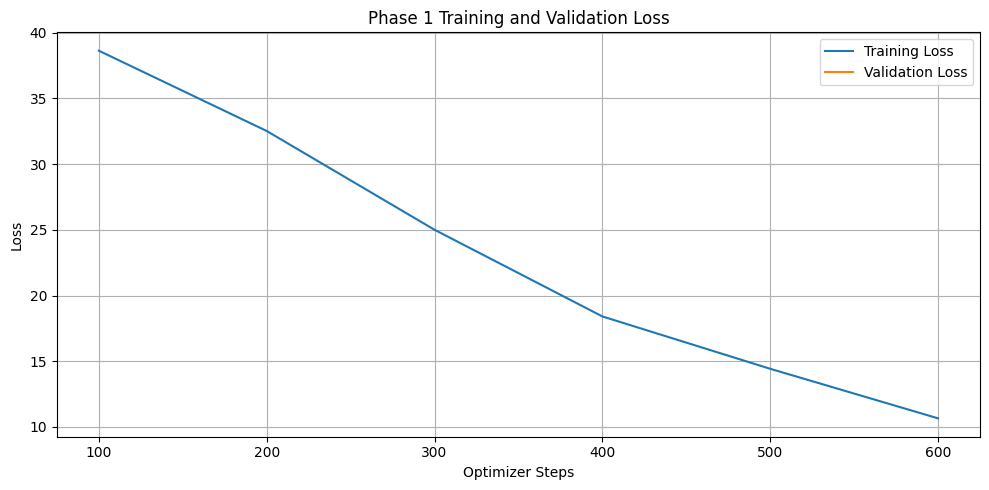

Loss plot saved to: /kaggle/working/cs781_phase1_full/training_validation_loss.png
Final model saved to: /kaggle/working/cs781_phase1_full/legal-gpt2-final


In [16]:
# ============================================================
# CELL 3 — Training loop (replaces §10 TrainingArguments, §11 Trainer, §12 perplexity,
#          §13 loss plot and §14 save).  Plain PyTorch, no HF Trainer.
# Fill every ########## before running.
# ============================================================
import os, time, json, math, pickle
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# ---------------- hyperparameters (yours to fill) ----------------
MICRO_BATCH_SIZE  = 4      # sequences per forward/backward pass
GRAD_ACCUM_STEPS  = 32      # micro-batches per optimizer step
LEARNING_RATE     = 3e-4     # Aligned with your previous TrainingArguments
WEIGHT_DECAY      = 0.1      # Standard for AdamW in GPT models[cite: 1]
BETAS             = (0.9, 0.95) # Standard AdamW betas for LLM pre-training
WARMUP_STEPS      = 500      # Aligned with your previous TrainingArguments[cite: 1]
MIN_LR_RATIO      = 0.1      # Decays to 10% of the peak learning rate (3e-5)
GRAD_CLIP         = 1.0      # Standard max gradient norm to prevent exploding gradients
LOG_EVERY         = 100      # Aligned with previous logging_steps[cite: 1]
EVAL_EVERY        = 1000     # Aligned with previous eval_steps[cite: 1]
EVAL_MAX_BATCHES  = 100      # Validates on a subset for speed (use None for full validation)
SAVE_EVERY        = 1000     # Aligned with previous save_steps[cite: 1]
MAX_TRAIN_SECONDS = 6 * 3600 # wall-clock safety cap for this session (saves, then stops)

# ---------------- not hyperparameters ----------------
RESUME  = False                    # set True to continue from ckpt.pt after a crashed / stopped session
USE_AMP = torch.cuda.is_available()   # fp16 mixed precision on GPU (same as the starter's fp16=True)

os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)
CKPT_PATH = os.path.join(MODEL_OUTPUT_DIR, "ckpt.pt")

# ---------------- bookkeeping ----------------
n_train_blocks   = len(train_dataset)
micro_per_epoch  = n_train_blocks // MICRO_BATCH_SIZE
steps_per_epoch  = micro_per_epoch // GRAD_ACCUM_STEPS
TOTAL_STEPS      = EPOCHS * steps_per_epoch
assert TOTAL_STEPS > 0, "no optimizer steps: lower MICRO_BATCH_SIZE / GRAD_ACCUM_STEPS or use more data"
tokens_per_step  = MICRO_BATCH_SIZE * GRAD_ACCUM_STEPS * (TRAIN_BLOCK_SIZE - 1)   # block of T gives T-1 predictions
print(f"train blocks {n_train_blocks:,} | optimizer steps {TOTAL_STEPS:,} | tokens/step {tokens_per_step:,} "
      f"| total tokens seen {TOTAL_STEPS * tokens_per_step:,}")


def lr_at(step):
    """Linear warmup, then cosine decay to LEARNING_RATE * MIN_LR_RATIO. `step` = completed optimizer steps."""
    if step < WARMUP_STEPS:
        return LEARNING_RATE * (step + 1) / WARMUP_STEPS
    progress = min(1.0, (step - WARMUP_STEPS) / max(1, TOTAL_STEPS - WARMUP_STEPS))
    cos = 0.5 * (1.0 + math.cos(math.pi * progress))
    return LEARNING_RATE * (MIN_LR_RATIO + (1.0 - MIN_LR_RATIO) * cos)


_perm_cache = {}
def get_micro_batch(m):
    """m = global micro-batch counter. Fixed shuffle per epoch (seeded) so resuming sees the same data order."""
    epoch, i = divmod(m, micro_per_epoch)
    if epoch not in _perm_cache:
        _perm_cache.clear()
        g = torch.Generator().manual_seed(SEED + epoch)
        _perm_cache[epoch] = torch.randperm(n_train_blocks, generator=g).numpy()
    idx = _perm_cache[epoch][i * MICRO_BATCH_SIZE:(i + 1) * MICRO_BATCH_SIZE]
    return torch.from_numpy(train_dataset.blocks[idx].astype(np.int64))


def lm_loss(batch):
    """batch: (B, T) token ids on device. Predict token t+1 from tokens <= t."""
    inputs, targets = batch[:, :-1], batch[:, 1:]
    with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
        logits = model(inputs)
    return F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), targets.reshape(-1))


@torch.no_grad()
def evaluate(max_batches=None):
    """Mean next-token cross-entropy over the validation blocks (all of them if max_batches is None)."""
    model.eval()
    n_batches = math.ceil(len(val_dataset) / MICRO_BATCH_SIZE)
    if max_batches:
        n_batches = min(n_batches, max_batches)
    total, count = 0.0, 0
    for b in range(n_batches):
        blk = val_dataset.blocks[b * MICRO_BATCH_SIZE:(b + 1) * MICRO_BATCH_SIZE]
        batch = torch.from_numpy(blk.astype(np.int64)).to(device)
        inputs, targets = batch[:, :-1], batch[:, 1:]
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(inputs)
        total += F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), targets.reshape(-1), reduction="sum").item()
        count += targets.numel()
    model.train()
    return total / count


# ---------------- optimizer ----------------
decay_params    = [p for p in model.parameters() if p.ndim >= 2]
no_decay_params = [p for p in model.parameters() if p.ndim < 2]
optimizer = torch.optim.AdamW(
    [{"params": decay_params, "weight_decay": WEIGHT_DECAY},
     {"params": no_decay_params, "weight_decay": 0.0}],
    lr=LEARNING_RATE, betas=BETAS,
)
scaler = torch.amp.GradScaler(device.type, enabled=USE_AMP)

step, train_log, eval_log = 0, [], []


def save_checkpoint():
    tmp = CKPT_PATH + ".tmp"
    torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(), "scaler": scaler.state_dict(),
                "step": step, "train_log": train_log, "eval_log": eval_log, "config": asdict(cfg)}, tmp)
    os.replace(tmp, CKPT_PATH)


if os.path.exists(CKPT_PATH):
    if RESUME:
        ck = torch.load(CKPT_PATH, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"]); scaler.load_state_dict(ck["scaler"])
        step, train_log, eval_log = ck["step"], ck["train_log"], ck["eval_log"]
        print(f"Resumed from step {step}")
    else:
        print("WARNING: ckpt.pt exists but RESUME=False -> it will be overwritten at the first save.")

# ---------------- sanity check before spending hours ----------------
# A model that has learned nothing should score about ln(vocab_size). A much larger number means the
# initial weights are badly scaled (the first steps would be wasted just fixing that).
_init_loss = evaluate(1)
print(f"Initial validation loss: {_init_loss:.2f}   (uniform guess = ln(vocab) = {math.log(cfg.vocab_size):.2f})")

# ---------------- train ----------------
model.train()
t_start = time.time()
t_last, stopped_by_time = time.time(), False
pbar = tqdm(total=TOTAL_STEPS, initial=step, desc="Training")

while step < TOTAL_STEPS:
    lr = lr_at(step)
    for group in optimizer.param_groups:
        group["lr"] = lr

    loss_sum = 0.0
    for micro in range(GRAD_ACCUM_STEPS):
        batch = get_micro_batch(step * GRAD_ACCUM_STEPS + micro).to(device)
        loss = lm_loss(batch) / GRAD_ACCUM_STEPS
        scaler.scale(loss).backward()
        loss_sum += loss.item()
    if not math.isfinite(loss_sum):
        raise RuntimeError(f"loss became {loss_sum} at step {step}; lower the learning rate / check the setup")

    scaler.unscale_(optimizer)
    grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP).item()
    scaler.step(optimizer)
    scaler.update()
    optimizer.zero_grad(set_to_none=True)
    step += 1
    pbar.update(1)
    pbar.set_postfix(loss=f"{loss_sum:.3f}", lr=f"{lr:.2e}")

    if step % LOG_EVERY == 0 or step == TOTAL_STEPS:
        now = time.time()
        tok_s = LOG_EVERY * tokens_per_step / max(1e-9, now - t_last)
        t_last = now
        train_log.append({"step": step, "loss": loss_sum, "lr": lr, "grad_norm": grad_norm, "tok_per_s": tok_s})
    if step % EVAL_EVERY == 0:
        val_loss = evaluate(EVAL_MAX_BATCHES)
        eval_log.append({"step": step, "val_loss": val_loss})
        tqdm.write(f"step {step}: val_loss {val_loss:.4f} (ppl {math.exp(val_loss):.2f})")
    if step % SAVE_EVERY == 0:
        save_checkpoint()
    if time.time() - t_start > MAX_TRAIN_SECONDS:
        stopped_by_time = True
        save_checkpoint()
        break

pbar.close()
training_seconds = time.time() - t_start
print(f"Training stopped at step {step}/{TOTAL_STEPS}" + ("  (STOPPED BY TIME CAP — lr schedule did not finish)" if stopped_by_time else ""))
print(f"Training time this session: {training_seconds / 3600:.2f} h")
if train_log:
    print(f"Last logged speed: {train_log[-1]['tok_per_s']:,.0f} tokens/sec")

# ---------------- final evaluation (all validation blocks) ----------------
eval_loss = evaluate(None)
perplexity = math.exp(eval_loss)
print(f"Validation loss: {eval_loss:.6f}")
print(f"Validation perplexity: {perplexity:.4f}")

# ---------------- plot ----------------
plt.figure(figsize=(10, 5))
plt.plot([r["step"] for r in train_log], [r["loss"] for r in train_log], label="Training Loss")
plt.plot([r["step"] for r in eval_log], [r["val_loss"] for r in eval_log], label="Validation Loss")
plt.xlabel("Optimizer Steps"); plt.ylabel("Loss"); plt.title("Phase 1 Training and Validation Loss")
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=200)
plt.show()
print("Loss plot saved to:", LOSS_PLOT_PATH)

# ---------------- save final model + tokenizer + logs ----------------
torch.save({"model": model.state_dict(), "config": asdict(cfg)}, os.path.join(MODEL_OUTPUT_DIR, "model_final.pt"))
tokenizer.cache = {}                                  # keep the pickle small
with open(os.path.join(MODEL_OUTPUT_DIR, "bpe_tokenizer.pkl"), "wb") as f:
    pickle.dump(tokenizer, f)
with open(os.path.join(MODEL_OUTPUT_DIR, "train_summary.json"), "w") as f:
    json.dump({"config": asdict(cfg), "n_params": n_params, "steps": step, "total_steps": TOTAL_STEPS,
               "stopped_by_time": stopped_by_time, "val_loss": eval_loss, "val_ppl": perplexity,
               "tokens_seen": step * tokens_per_step, "train_log": train_log, "eval_log": eval_log}, f, indent=2)
print("Final model saved to:", MODEL_OUTPUT_DIR)

In [17]:
# from transformers import TrainingArguments

# training_args = TrainingArguments(
#     output_dir=MODEL_OUTPUT_DIR,
#     num_train_epochs=EPOCHS,
#     per_device_train_batch_size=4,
#     per_device_eval_batch_size=4,
#     gradient_accumulation_steps=2,
#     learning_rate=3e-4,
#     weight_decay=0.1,
#     warmup_steps=500,
#     lr_scheduler_type="cosine",
#     fp16=torch.cuda.is_available(),
#     eval_strategy="steps",
#     eval_steps=1000,
#     logging_steps=100,
#     save_steps=1000,
#     save_total_limit=2,
#     seed=SEED,
#     report_to="none",
#     logging_dir=os.path.join(OUTPUT_DIR, "logs")
# )

## 11. Training

In [18]:
# from transformers import Trainer

# trainer = Trainer(
#     model=model,
#     args=training_args,
#     train_dataset=train_dataset,
#     eval_dataset=val_dataset,
#     data_collator=data_collator,
#     processing_class=tokenizer
# )

# start_time = time.time()

# trainer.train()

# training_time = (time.time() - start_time)

# tokens_per_epoch = (len(train_dataset) * TRAIN_BLOCK_SIZE)

# total_tokens = (tokens_per_epoch * EPOCHS)

# tokens_per_second = (total_tokens / training_time)

# print(f"Training time: {training_time / 3600:.2f} hours")
# print(f"Training speed: {tokens_per_second:,.0f} tokens/sec")

## 12. Perplexity

In [19]:
# eval_results = trainer.evaluate()
# eval_loss = eval_results["eval_loss"]
# perplexity = math.exp(eval_loss)
# print(f"Validation loss: {eval_loss:.6f}")
# print(f"Validation perplexity: {perplexity:.4f}")

## 13. Plot Training and Validation Loss

In [20]:
# import matplotlib.pyplot as plt

# logs = trainer.state.log_history

# train_steps = []
# train_loss = []
# eval_steps = []
# eval_loss = []

# for log in logs:
#     if ("loss" in log and "step" in log):
#         train_steps.append(log["step"])
#         train_loss.append(log["loss"])
#     if ("eval_loss" in log and "step" in log):
#         eval_steps.append(log["step"])
#         eval_loss.append(log["eval_loss"])

# plt.figure(figsize=(10, 5))
# plt.plot(train_steps, train_loss, label="Training Loss")
# plt.plot(eval_steps, eval_loss, label="Validation Loss")
# plt.xlabel("Training Steps")
# plt.ylabel("Loss")
# plt.title("Phase 1 Training and Validation Loss")
# plt.legend()
# plt.grid(True)
# plt.tight_layout()
# plt.savefig(LOSS_PLOT_PATH, dpi=200)
# plt.show()

# print("Loss plot saved to:")
# print(LOSS_PLOT_PATH)

## 14. Save Final Model to Kaggle Output

In [21]:
# trainer.save_model(MODEL_OUTPUT_DIR)
# tokenizer.save_pretrained(MODEL_OUTPUT_DIR)

# print("Final model saved to:")
# print(MODEL_OUTPUT_DIR)

## 15. Push Model to Hugging Face Hub

In [22]:
# model.push_to_hub(HF_MODEL_REPO, token=HF_TOKEN)
# tokenizer.push_to_hub(HF_MODEL_REPO, token=HF_TOKEN)

# print("Model and tokenizer pushed successfully.")

## 16. Load Test Data from HuggingFace

In [23]:
test_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TEST_FILE,
    repo_type="dataset",
    token=HF_TOKEN
)

print("Test file:", test_file_path)

test.json:   0%|          | 0.00/3.03M [00:00<?, ?B/s]

Test file: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Test/test.json


## 17. Load Test Prompts

In [24]:
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

print("Number of test examples:", len(test_data))

Number of test examples: 1000


## 18. Load Final Model for Generation

In [25]:
# ============================================================
# CELL 4 — Generation (replaces §18 load model, §19 generate_batch, §20 predictions loop)
# Keep §16/§17 (load test prompts), §21 (save prediction.json) and §22 (zip) as they are.
# Fill every ########## before running.
# ============================================================
GENERATION_BATCH_SIZE = 32     # Aligned with your previous Cell 20 configuration[cite: 1]
SUPPRESS_EOS          = False  # False allows the model to end sentences naturally. Set to True only if you strictly want to force 128 words.

UNK_ID = SPECIAL_TOKENS.index("<unk>")

# Reload the saved weights exactly as a fresh session would (proves the saved file works).
_ck = torch.load(os.path.join(MODEL_OUTPUT_DIR, "model_final.pt"), map_location=device, weights_only=False)
model = DecoderLM(LMConfig(**_ck["config"])).to(device)
model.load_state_dict(_ck["model"])
model.eval()
print(f"Loaded model: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M parameters on {device}")


@torch.no_grad()
def sample_next(logits, temperature, top_p):
    """logits: (B, V) float. Temperature + nucleus (top-p) sampling -> (B, 1) token ids."""
    probs = F.softmax(logits / max(temperature, 1e-5), dim=-1)
    sorted_probs, sorted_idx = torch.sort(probs, descending=True, dim=-1)
    cum = sorted_probs.cumsum(dim=-1)
    sorted_probs = sorted_probs.masked_fill(cum - sorted_probs > top_p, 0.0)   # keep smallest set with mass >= top_p
    sorted_probs = sorted_probs / sorted_probs.sum(dim=-1, keepdim=True)
    choice = torch.multinomial(sorted_probs, 1)
    return sorted_idx.gather(-1, choice)


@torch.no_grad()
def generate_equal_length(prompt_rows, max_new_tokens):
    """prompt_rows: list of equal-length token-id lists (no padding needed). Returns list of new-token lists."""
    x = torch.tensor(prompt_rows, dtype=torch.long, device=device)
    banned = [PAD_ID, UNK_ID, BOS_ID] + ([EOS_ID] if SUPPRESS_EOS else [])
    for _ in range(max_new_tokens):
        ctx = x[:, -cfg.max_seq_len:]
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(ctx)[:, -1, :]
        logits = logits.float()
        logits[:, banned] = float("-inf")
        x = torch.cat([x, sample_next(logits, TEMPERATURE, TOP_P)], dim=1)
    return x[:, -max_new_tokens:].tolist()


def ids_to_text(ids):
    if EOS_ID in ids:
        ids = ids[:ids.index(EOS_ID)]
    return tokenizer.decode([t for t in ids if t >= NUM_SPECIAL])


# ---------------- run over the test prompts ----------------
items = list(test_data.items())
if NUM_TEST_PROMPTS:
    items = items[:NUM_TEST_PROMPTS]

max_prompt_tokens = MODEL_CONTEXT_LENGTH - MAX_GENERATION_TOKENS
enc = [tokenizer.encode(rec["text"])[-max_prompt_tokens:] for _, rec in items]   # keep the END of long prompts

# The model has no padding mask, so batch prompts of (almost) equal length and crop each prompt in a
# batch to the shortest one (dropping only its oldest tokens) instead of padding.
order = sorted(range(len(items)), key=lambda i: len(enc[i]))
raw, dropped_tokens = {}, 0
t0 = time.time()
for s in range(0, len(order), GENERATION_BATCH_SIZE):
    batch_idx = order[s:s + GENERATION_BATCH_SIZE]
    L = min(len(enc[i]) for i in batch_idx)
    dropped_tokens += sum(len(enc[i]) - L for i in batch_idx)
    new_ids = generate_equal_length([enc[i][-L:] for i in batch_idx], MAX_GENERATION_TOKENS)
    for i, ids in zip(batch_idx, new_ids):
        raw[i] = " ".join(ids_to_text(ids).split()[:TARGET_GENERATION_WORDS])
    done = min(s + GENERATION_BATCH_SIZE, len(order))
    print(f"Completed {done}/{len(order)} ({100 * done / len(order):.1f}%) | {(time.time() - t0) / 60:.1f} min")

predictions = {str(items[i][0]): {"text": raw[i]} for i in range(len(items))}   # original id order

wc = [len(v["text"].split()) for v in predictions.values()]
print(f"Predictions: {len(predictions)} | words per prediction: min {min(wc)}, mean {sum(wc) / len(wc):.1f}, max {max(wc)} "
      f"| shorter than {TARGET_GENERATION_WORDS}: {sum(w < TARGET_GENERATION_WORDS for w in wc)}")
print(f"Avg prompt tokens dropped by length-batching: {dropped_tokens / len(items):.1f}")
assert SMOKE or len(predictions) == len(test_data), "missing test IDs — do not submit"

Loaded model: 98.41M parameters on cuda
Completed 32/1000 (3.2%) | 3.4 min
Completed 64/1000 (6.4%) | 7.1 min
Completed 96/1000 (9.6%) | 10.9 min
Completed 128/1000 (12.8%) | 14.7 min
Completed 160/1000 (16.0%) | 18.5 min
Completed 192/1000 (19.2%) | 22.4 min
Completed 224/1000 (22.4%) | 26.3 min
Completed 256/1000 (25.6%) | 30.2 min
Completed 288/1000 (28.8%) | 34.1 min
Completed 320/1000 (32.0%) | 38.1 min
Completed 352/1000 (35.2%) | 42.1 min
Completed 384/1000 (38.4%) | 46.2 min
Completed 416/1000 (41.6%) | 50.2 min
Completed 448/1000 (44.8%) | 54.3 min
Completed 480/1000 (48.0%) | 58.5 min
Completed 512/1000 (51.2%) | 62.7 min
Completed 544/1000 (54.4%) | 66.9 min
Completed 576/1000 (57.6%) | 71.1 min
Completed 608/1000 (60.8%) | 75.4 min
Completed 640/1000 (64.0%) | 79.7 min
Completed 672/1000 (67.2%) | 84.1 min
Completed 704/1000 (70.4%) | 88.5 min
Completed 736/1000 (73.6%) | 92.9 min
Completed 768/1000 (76.8%) | 97.4 min
Completed 800/1000 (80.0%) | 101.9 min
Completed 832/100

In [26]:
# from transformers import AutoTokenizer, GPT2LMHeadModel
# import torch

# generation_tokenizer = AutoTokenizer.from_pretrained(MODEL_OUTPUT_DIR)
# generation_model = GPT2LMHeadModel.from_pretrained(MODEL_OUTPUT_DIR)

# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# generation_model = generation_model.to(device)
# generation_model.eval()
# generation_model.config.use_cache = True

# print("Device:", device)
# print(f"Parameters: {sum(p.numel() for p in generation_model.parameters()) / 1e6:.2f}M")

## 19. Generate 128 Words
#### (words, not tokens)

In [27]:
# def generate_batch(prompts, model, tokenizer, device, target_words=128):
#     inputs = tokenizer(
#         prompts,
#         return_tensors="pt",
#         padding=True,
#         truncation=True,
#         max_length=MODEL_CONTEXT_LENGTH - MAX_GENERATION_TOKENS
#     )

#     inputs = {key: value.to(device) for key, value in inputs.items()}
#     input_lengths = inputs["attention_mask"].sum(dim=1)

#     with torch.inference_mode():
#         outputs = model.generate(
#             **inputs,
#             max_new_tokens=MAX_GENERATION_TOKENS,
#             do_sample=True,
#             temperature=TEMPERATURE,
#             top_p=TOP_P,
#             pad_token_id=tokenizer.eos_token_id,
#         )

#     predictions = []
#     for i in range(len(prompts)):
#         generated_tokens = outputs[i, input_lengths[i]:]
#         generated_text = tokenizer.decode(generated_tokens, skip_special_tokens=True)
#         generated_words = generated_text.split()
#         generated_words = generated_words[:target_words]
#         predictions.append(" ".join(generated_words))

#     return predictions

## 20. Generate Predictions for the Test Set

In [28]:
# predictions = {}
# GENERATION_BATCH_SIZE = 32

# items = list(test_data.items())
# total_examples = len(items)
# print(f"Total test examples: {total_examples}")

# for start in range(0, total_examples, GENERATION_BATCH_SIZE):
#     batch = items[start:start + GENERATION_BATCH_SIZE]
#     batch_ids = [str(example_id) for example_id, _ in batch]
#     batch_prompts = [record["text"] for _, record in batch]

#     batch_predictions = generate_batch(
#         prompts=batch_prompts,
#         model=generation_model,
#         tokenizer=generation_tokenizer,
#         device=device,
#         target_words=128
#     )

#     for example_id, prediction in zip(batch_ids, batch_predictions):
#         predictions[example_id] = {"text": prediction}

#     completed = start + len(batch)
#     print(f"Completed {completed}/{total_examples} ({100 * completed / total_examples:.1f}%)")

## 21. Save prediction.json

In [29]:
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(
        predictions,
        f,
        ensure_ascii=False,
        indent=2
    )

print("prediction.json saved:")
print(PREDICTION_PATH)

prediction.json saved:
/kaggle/working/cs781_phase1_full/prediction.json


## 22. Create CodaBench Submission ZIP

In [30]:
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(PREDICTION_PATH, arcname="prediction.json")

print("Codabench submission created:")
print(SUBMISSION_ZIP)

Codabench submission created:
/kaggle/working/cs781_phase1_full/submission.zip
